# A whole-transcriptome Atera run from Arraylake, inside two levels of zip

Atera is 10x's whole-transcriptome in-situ assay. 10x publish this [cervical cancer
preview](https://www.10xgenomics.com/datasets/atera-wta-ffpe-human-cervical-cancer) as **one 89 GB `outs.zip` and nothing else**. There is no standalone counts
file and no standalone transcripts file. A reader has no other file to open.
`earthmover-demos/atera-cervical-virtual` opens that bundle all the same, and it holds byte ranges
instead of data. It holds 47,599 ranges for the elements.

The archive nests files but hides no data, and that makes the bundle reachable. The outputs are
`.zarr.zip` members of `outs.zip`. Their chunks are members of *those* archives. Both levels are
**stored**, not deflated. So a chunk sits at

    (where outs.zip puts transcripts.zarr.zip) + (where that puts the chunk)

That sum is one absolute range into one published object. Stored offsets compose, and deflated
offsets do not. Thus this store has none of the morphology images from the same archive.

Most of what follows looks like ordinary data access. The byte counters show that no step copied
any data.

## Open the store

This step needs no special handling. The TIFF parser that wrote the image references also supplies
their JPEG 2000 codec. After this cell, `spatialdata` does what it always does.

In [1]:
import warnings

warnings.simplefilter("ignore")

import matplotlib.pyplot as plt
import numpy as np
import spatialdata as sd  # noqa: F401
import spatialdata_plot   # noqa: F401
from arraylake import Client
from arraylake import config as al_config

import icechunk_spatialdata as isd

# The published repo is on prod. A local config can point the client at dev.
al_config.set({"service.uri": "https://api.earthmover.io"})

session = Client().get_repo("earthmover-demos/atera-cervical-virtual", config=isd.repository_config()).readonly_session("main")
isd.bounded_reads()
with isd.parquet_in_store():
    sdata = sd.read_zarr(session.store)
sdata

SpatialData object
├── Images
│     └── 'he_image': DataTree[cyx] (3, 47337, 90368), (3, 23668, 45184), (3, 11834, 22592), (3, 5917, 11296), (3, 2958, 5648), (3, 1479, 2824), (3, 739, 1412), (3, 369, 706), (3, 184, 353), (3, 92, 176)
├── Labels
│     ├── 'cell_labels': DataArray[yx] (41877, 42001)
│     └── 'nucleus_labels': DataArray[yx] (41877, 42001)
└── Tables
      └── 'table': AnnData (717576, 27105)
with coordinate systems:
    ▸ 'global', with elements:
        he_image (Images), cell_labels (Labels), nucleus_labels (Labels)

## What the repository actually holds

The unit of size for this store is the *reference*, not the gigabyte. Every chunk of every element
below is a byte range in 10x's object. The store holds actual bytes only for the cell identifiers,
the gene names and two annotation columns.

In [2]:
root = __import__("zarr").open_group(session.store, mode="r")
print(root.attrs["source"], "\n")
for name, node in sorted(root.members(max_depth=3)):
    if hasattr(node, "shape"):
        print(f"  {name:52} {str(node.shape):>24} {node.dtype}")

s3://10x.files/samples/atera/dev/WTA_Preview_FFPE_Cervical_Cancer/WTA_Preview_FFPE_Cervical_Cancer_outs.zip 



  images/he_image/s0                                          (3, 47337, 90368) uint8
  images/he_image/s1                                          (3, 23668, 45184) uint8
  images/he_image/s2                                          (3, 11834, 22592) uint8
  images/he_image/s3                                           (3, 5917, 11296) uint8
  images/he_image/s4                                            (3, 2958, 5648) uint8
  images/he_image/s5                                            (3, 1479, 2824) uint8
  images/he_image/s6                                             (3, 739, 1412) uint8
  images/he_image/s7                                              (3, 369, 706) uint8
  images/he_image/s8                                              (3, 184, 353) uint8
  images/he_image/s9                                               (3, 92, 176) uint8
  labels/cell_labels/s0                                          (41877, 42001) uint32
  labels/nucleus_labels/s0                           

## The counts, cell-major, untransposed

The expression matrix needs no conversion. 10x publish the same 611 million values twice: once
with a feature index, once with a cell index. **CSC over (genes x cells) is CSR over (cells x
genes)**. So the cell-major copy is an AnnData `X` exactly as it is. It needs no transpose and no
re-encoding: the store holds three arrays as references.

Note the dtypes. `indices` is `uint16`. That type is enough for 27,105 features, but not for
717,576 cells. A converter would widen it and double the size of the array.

In [3]:
table = sdata.tables["table"]
X = table.X
print(f"{table.n_obs:,} cells x {table.n_vars:,} features, {X.nnz:,} stored values")
print(f"X {X.dtype}, indices {X.indices.dtype}, indptr {X.indptr.dtype}")
table.obs.head()

717,576 cells x 27,105 features, 611,348,263 stored values
X uint32, indices uint16, indptr uint32


,cell_centroid_x,cell_centroid_y,cell_area,nucleus_centroid_x,nucleus_centroid_y,nucleus_area,z_level,nucleus_count,region,cell_index
aaaaahkl-1,24.557163,356.760437,56.983010,24.683521,356.535675,38.741222,0.0,1.0,cell_labels,1
aaaabeha-1,21.358480,371.641663,44.565952,21.371239,371.516357,34.677458,0.0,1.0,cell_labels,2
aaaabmoe-1,27.345419,368.845734,84.074774,26.349880,367.500702,39.689434,0.0,1.0,cell_labels,3
aaaacmod-1,16.825048,396.867096,54.680210,17.015764,397.067108,35.128987,0.0,1.0,cell_labels,4
aaaafdoj-1,19.836916,407.070068,27.452987,19.972933,407.252014,25.150187,0.0,1.0,cell_labels,5


### 27,105 columns are not 27,105 genes

The dataset has one column that can cause an error. That column has the type `aggregate_gene` and
the name `Total transcripts`. It is a per-cell library size *inside the matrix*. It equals the sum
of the gene columns exactly. Thus a row sum over all columns counts every gene twice. A
normalization on the unfiltered `X` starts from totals that are double their true value.

In [4]:
kinds = table.var["feature_types"].value_counts()
print(kinds.to_string(), "\n")

genes = np.flatnonzero(table.var["feature_types"].to_numpy() == "gene")
aggregate = np.flatnonzero(table.var["feature_types"].to_numpy() == "aggregate_gene")
row = table.X[12345]
dense = np.zeros(table.n_vars, dtype=np.int64)
dense[row.indices] = row.data
print(f"cell {table.obs_names[12345]}: "
      f"'Total transcripts' = {dense[aggregate].sum()}, "
      f"gene columns sum to {dense[genes].sum()}, "
      f"controls add {dense.sum() - dense[genes].sum() - dense[aggregate].sum()}")

feature_types
gene                         18028
negative_control_codeword     6390
unassigned_codeword           2543
negative_control_probe          81
genomic_control                 62
aggregate_gene                   1 



cell aeadaago-1: 'Total transcripts' = 493, gene columns sum to 493, controls add 1


## The per-cell metrics, one reference per column

`cell_summary` has one column per chunk, so each `obs` column is a single contiguous block. Thus a
column of 717,576 values is *one* byte range, and `obsm["spatial"]` is two. A converter would read
the array and write the same numbers back out.

The NaNs are real. A cell with no detected nucleus has no nucleus centroid and no nucleus area.

In [5]:
summary = table.obs[["cell_area", "nucleus_area", "nucleus_count"]].describe()
without = int(table.obs["nucleus_area"].isna().sum())
print(f"{without:,} of {table.n_obs:,} cells have no nucleus\n")
summary

7,036 of 717,576 cells have no nucleus



,cell_area,nucleus_area,nucleus_count
count,717576.000000,710540.000000,717576.000000
mean,62.592223,29.927936,1.002593
std,41.361479,18.938094,0.152829
min,1.715812,1.038518,0.000000
25%,35.174140,16.977505,1.000000
50%,51.474351,26.324164,1.000000
75%,78.114586,37.612399,1.000000
max,741.998261,336.931237,4.000000


## One image with references, and four without

10x publish the post-run H&E as its own object. It is uncompressed, with 1024x1024 tiles, and it
is *planar*. So it is already `(c, y, x)`, and it needs no codec and no transpose. Its ten pyramid
levels are 16,920 references. Reads go to the origin bucket, not to the CDN copy. The CDN copy
stalls under an S3 client.

The morphology images are the counter-example. They are also the reason that this store has no
`morphology_focus`. The archive deflates them, and 10x publish them nowhere else. A deflated member
is one Huffman-coded stream, so no tile of it has an addressable offset. The compression gives no
benefit for these images. On this sample, each of those images is *larger* deflated than stored.

In [6]:
he = sdata.images["he_image"]
for level, node in he.items():
    array = node["image"]
    print(f"  {level}: {tuple(array.dims)} {tuple(array.shape)} {array.dtype}")

  scale0: ('c', 'y', 'x') (3, 47337, 90368) uint8
  scale1: ('c', 'y', 'x') (3, 23668, 45184) uint8
  scale2: ('c', 'y', 'x') (3, 11834, 22592) uint8
  scale3: ('c', 'y', 'x') (3, 5917, 11296) uint8
  scale4: ('c', 'y', 'x') (3, 2958, 5648) uint8
  scale5: ('c', 'y', 'x') (3, 1479, 2824) uint8
  scale6: ('c', 'y', 'x') (3, 739, 1412) uint8
  scale7: ('c', 'y', 'x') (3, 369, 706) uint8
  scale8: ('c', 'y', 'x') (3, 184, 353) uint8
  scale9: ('c', 'y', 'x') (3, 92, 176) uint8


## Draw the data

No code below knows that the pixels are in someone else's bucket. We chose a small crop
deliberately: a reference-backed store reads exactly the tiles that a view touches.

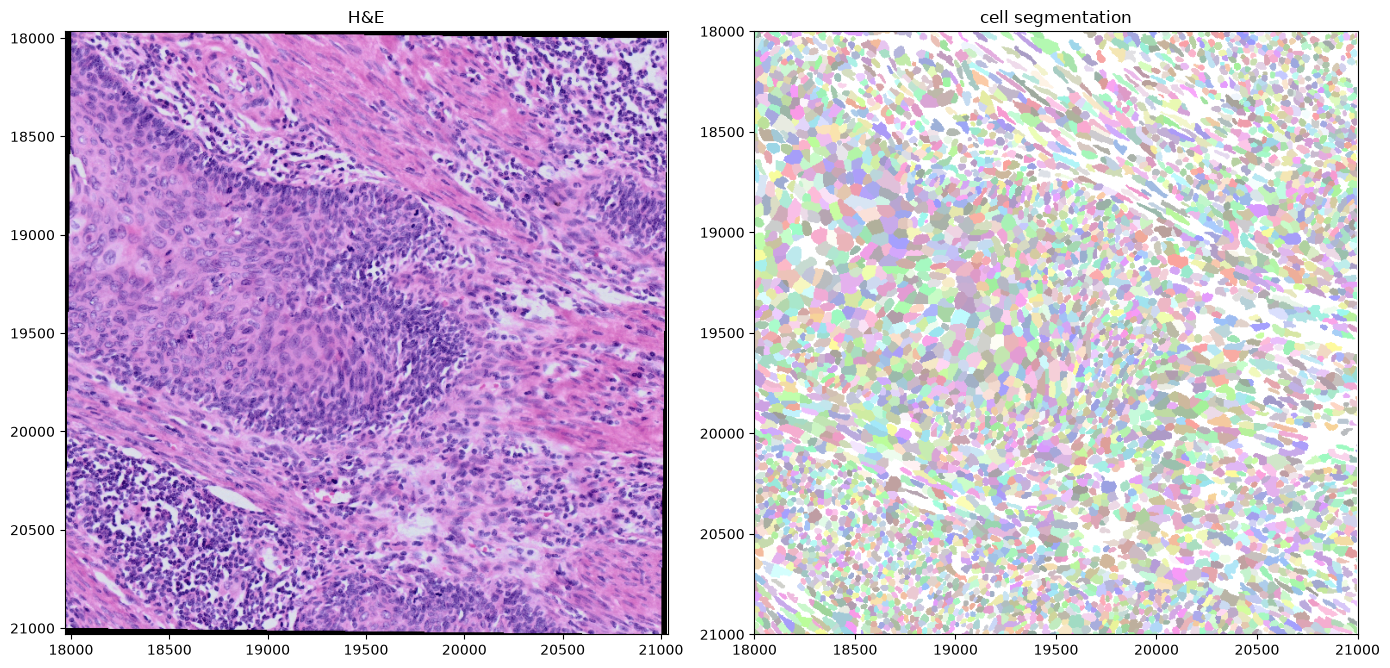

In [7]:
window = sd.bounding_box_query(
    sdata,
    axes=("x", "y"),
    min_coordinate=[18000, 18000],
    max_coordinate=[21000, 21000],
    target_coordinate_system="global",
    filter_table=True,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
window.pl.render_images("he_image").pl.show(ax=axes[0], title="H&E", coordinate_systems="global")
window.pl.render_labels("cell_labels").pl.show(
    ax=axes[1], title="cell segmentation", coordinate_systems="global")
fig.tight_layout()

## The transcripts

The store has 1.24 billion transcripts at the finest level of the pyramid, in 1,242 tiles. They
are *not* a SpatialData points element, and the store says so. A virtual Zarr array cannot span two
source arrays. Thus one array per source tile is the accurate encoding, and the concatenation
happens on read. The group's attributes hold the reason and the gene names.

In [8]:
grid = root["points_virtual"]["transcripts"]
tiles = sorted(name for name, _ in grid.members())
counts = [grid[t]["location"].shape[0] for t in tiles]
print(f"{len(tiles):,} tiles, {sum(counts):,} transcripts")
print(f"  {grid.attrs['reason']}\n")

names = grid.attrs["gene_names"]
tile = grid[tiles[len(tiles) // 2]]
where = np.asarray(tile["location"][:5])
which = np.asarray(tile["gene_identity"][:5]).ravel()
for (x, y, z), gene in zip(where, which):
    print(f"  ({x:9.2f}, {y:9.2f}, {z:6.2f})  {names[gene] if gene < len(names) else 'no-call'}")

1,242 tiles, 1,235,087,993 transcripts
  one array per source tile: a Zarr array cannot span two source arrays while virtual, so the tiles are concatenated on read rather than in the store



  (  6334.69,   7585.47,  18.67)  A1BG
  (  6404.50,   7744.84,  19.44)  A1BG
  (  6393.78,   7558.06,  20.11)  A1BG
  (  6264.66,   7508.20,  18.94)  A1BG
  (  6260.78,   7632.97,  17.92)  A1BG


## What it cost

A store that holds byte ranges is not a copy at all. It stays correct only while the publisher
keeps their bytes where they are. That is the trade-off.

In [9]:
logical = arrays = 0
for name, node in root.members(max_depth=4):
    if hasattr(node, "shape"):
        arrays += 1
        logical += int(np.prod(node.shape)) * node.dtype.itemsize

print(f"{arrays:,} arrays addressing {logical / 1e9:,.1f} GB of pixels, counts and coordinates")
print("held here: 47,599 element byte ranges plus the tiles view's re-emission of the H&E,")
print("the cell identifiers, the gene names and two obs columns")
print("\nabsent, and not by choice: morphology.ome.tif and the four morphology_focus channels,")
print("29 GB deflated inside the same archive, where every interior offset stops existing")

2,533 arrays addressing 69.3 GB of pixels, counts and coordinates
held here: 47,599 element byte ranges plus the tiles view's re-emission of the H&E,
the cell identifiers, the gene names and two obs columns

absent, and not by choice: morphology.ome.tif and the four morphology_focus channels,
29 GB deflated inside the same archive, where every interior offset stops existing
